# 01 - Exploratory data analysis: *who gets their order late?*

**Project:** OnTime - explainable late-delivery risk engine for e-commerce (Olist).
**Purpose of this notebook:** understand the target (`is_late`) before modelling anything.
We ask eight plain questions of the data and write down what each answer *implies* for the
features and for how we validate the model.

**How to read it:** every section follows the same rhythm - *question -> evidence (table/figure)
-> inference*. The inference cells are computed from the data (numbers are never typed by hand),
so they stay correct if the data or cut-offs change.

**Ground rules this notebook respects**
- All logic lives in `src/ontime/analysis/eda.py`; this notebook only imports and narrates.
- It uses the Phase 2 order table: **delivered orders only**, approved before the censoring
  cut-off, one row per order.
- Variables created here (distance, promised days...) are for *understanding*. Model features
  are built and leak-tested separately in Phase 4.
- **Target:** `is_late = 1` if the order was delivered on a calendar date *after* the promised
  date shown to the customer at checkout.

In [1]:
import warnings

warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

from ontime.config import load_config, project_path
from ontime.analysis import eda

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
CFG = load_config()
FIG = project_path(CFG["paths"]["figures_dir"])
show = lambda name: display(Image(filename=str(FIG / name)))  # show a saved report figure
pct = lambda v: f"{v:.1%}"

df = eda.add_eda_columns(eda.load_orders())
base_rate = df["is_late"].mean()

## 0. The data we are looking at
A quick fact sheet so every later number has context.

In [2]:
facts = pd.Series(
    {
        "orders (delivered, after filters)": f"{len(df):,}",
        "first approval": str(df["order_approved_at"].min().date()),
        "last approval": str(df["order_approved_at"].max().date()),
        "late orders": f"{int(df['is_late'].sum()):,}",
        "late rate": pct(base_rate),
        "distinct sellers (primary)": f"{df['primary_seller_id'].nunique():,}",
        "customer states": df["customer_state"].nunique(),
    }
)
facts.to_frame("value")

,value
"orders (delivered, after filters)","94,937"
first approval,2016-09-15
last approval,2018-08-18
late orders,"6,504"
late rate,6.9%
distinct sellers (primary),"2,928"
customer states,27


## 1. How imbalanced is the target?
**Why we ask:** if lateness is rare, a model that always says "on time" looks great on
accuracy while being useless. That decides which metric we can trust.

In [3]:
t = df["is_late"].value_counts().rename({0: "on time", 1: "late"}).to_frame("orders")
t["share"] = t["orders"] / t["orders"].sum()
display(t)
accuracy_of_always_on_time = 1 - base_rate
Markdown(f"""
**Inference.** Only **{pct(base_rate)}** of orders are late. A model that predicts "on time" for
every order would be **{pct(accuracy_of_always_on_time)} accurate** and catch *zero* late orders.
Therefore accuracy is meaningless here; we will judge models with **PR-AUC** (precision/recall
trade-off for the rare class), precision@k and lift, and keep a "predict the base rate" model as
the floor.
""")

,orders,share
is_late,,
on time,88433,0.931
late,6504,0.069



**Inference.** Only **6.9%** of orders are late. A model that predicts "on time" for
every order would be **93.1% accurate** and catch *zero* late orders.
Therefore accuracy is meaningless here; we will judge models with **PR-AUC** (precision/recall
trade-off for the rare class), precision@k and lift, and keep a "predict the base rate" model as
the floor.


## 2. Is lateness stable over time?
**Why we ask:** this decides how we split train/validation/test. If the late rate drifts or
spikes, a random split would leak the future into the past and flatter the model.

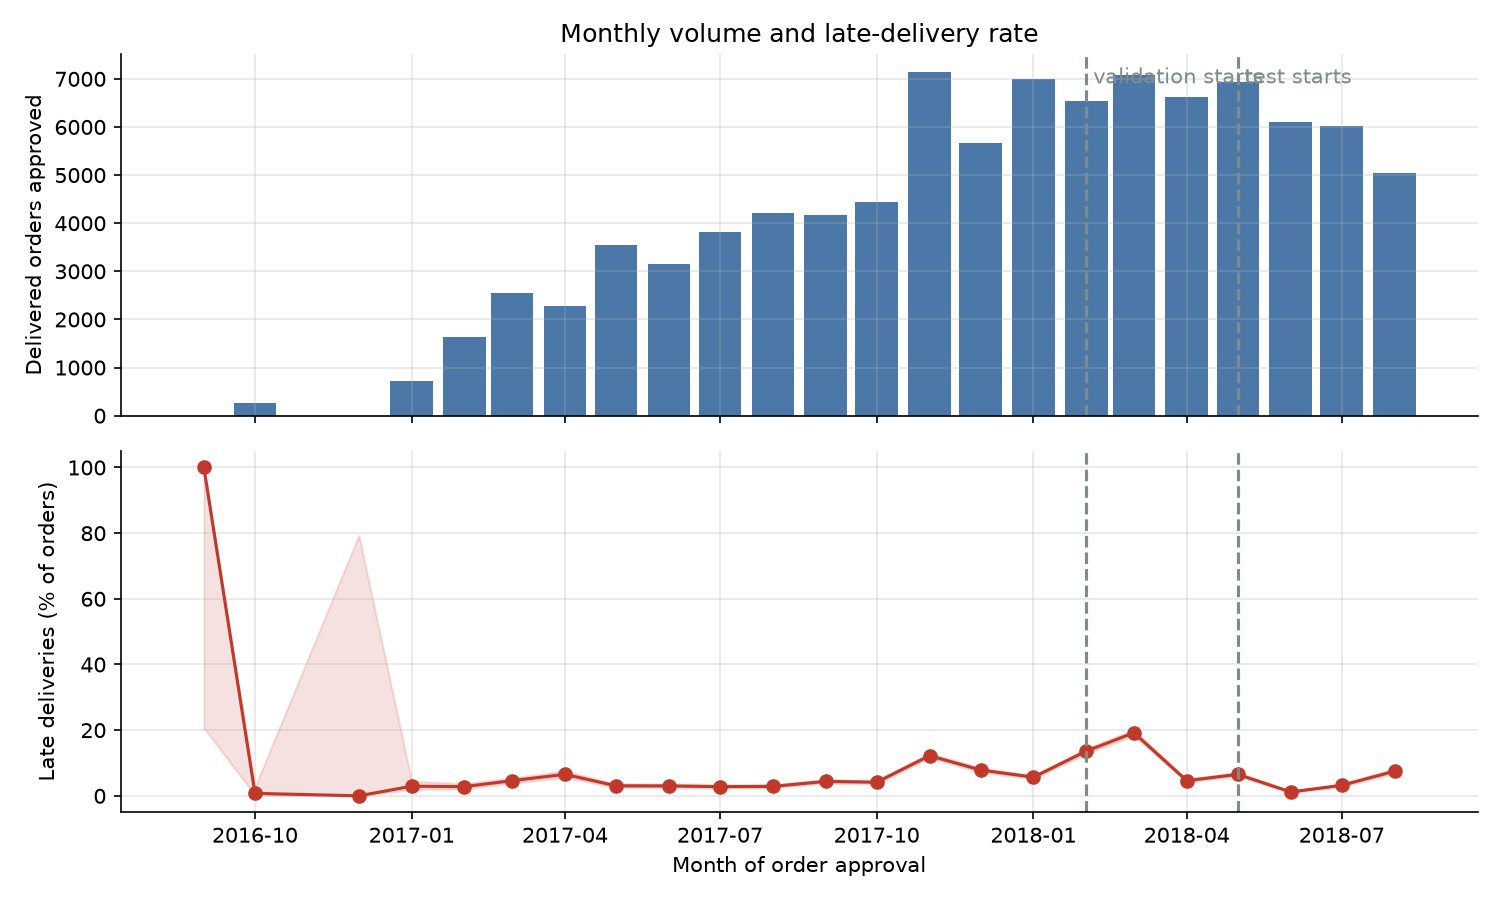


**Inference.**
- The late rate is **not constant**: from **1.2%** in Jun 2018
  to **19.2%** in Mar 2018 (months with at least 1,000 orders).
- These swings are not sampling noise: the widest 95% interval half-width in those months is only
  **1.0 percentage points**, far smaller than the
  swings themselves. They look like *episodes* (a holiday rush, a logistics crunch).
- **Consequence 1:** we split **by time** (train past -> validate -> test future). A random split
  would let the model see "neighbouring" orders from the same crisis week, overstating skill.
- **Consequence 2:** the model must be robust to *regime changes*; we will report performance
  **month by month** on the test set and expect calibration to drift.
- **Consequence 3:** a system-wide "recent late rate" feature (leak-safe) is a promising signal.


In [4]:
monthly = eda.plot_monthly_late_rate(df, CFG["splits"])
show("eda_monthly_late_rate.png")
big = monthly[monthly["orders"] >= 1000]  # ignore the tiny first months of 2016
hi, lo = big.loc[big["late_rate"].idxmax()], big.loc[big["late_rate"].idxmin()]
Markdown(f"""
**Inference.**
- The late rate is **not constant**: from **{pct(lo["late_rate"])}** in {lo["approve_month"]:%b %Y}
  to **{pct(hi["late_rate"])}** in {hi["approve_month"]:%b %Y} (months with at least 1,000 orders).
- These swings are not sampling noise: the widest 95% interval half-width in those months is only
  **{(big["ci_high"] - big["ci_low"]).max() / 2 * 100:.1f} percentage points**, far smaller than the
  swings themselves. They look like *episodes* (a holiday rush, a logistics crunch).
- **Consequence 1:** we split **by time** (train past -> validate -> test future). A random split
  would let the model see "neighbouring" orders from the same crisis week, overstating skill.
- **Consequence 2:** the model must be robust to *regime changes*; we will report performance
  **month by month** on the test set and expect calibration to drift.
- **Consequence 3:** a system-wide "recent late rate" feature (leak-safe) is a promising signal.
""")

## 3. How generous is the promise? (promised days vs actual days)
**Why we ask:** lateness is a *comparison* between what was promised and what happened. If the
marketplace pads its estimates heavily, most orders have large slack and lateness is a
tail event; the interesting question becomes which orders eat all of that slack.

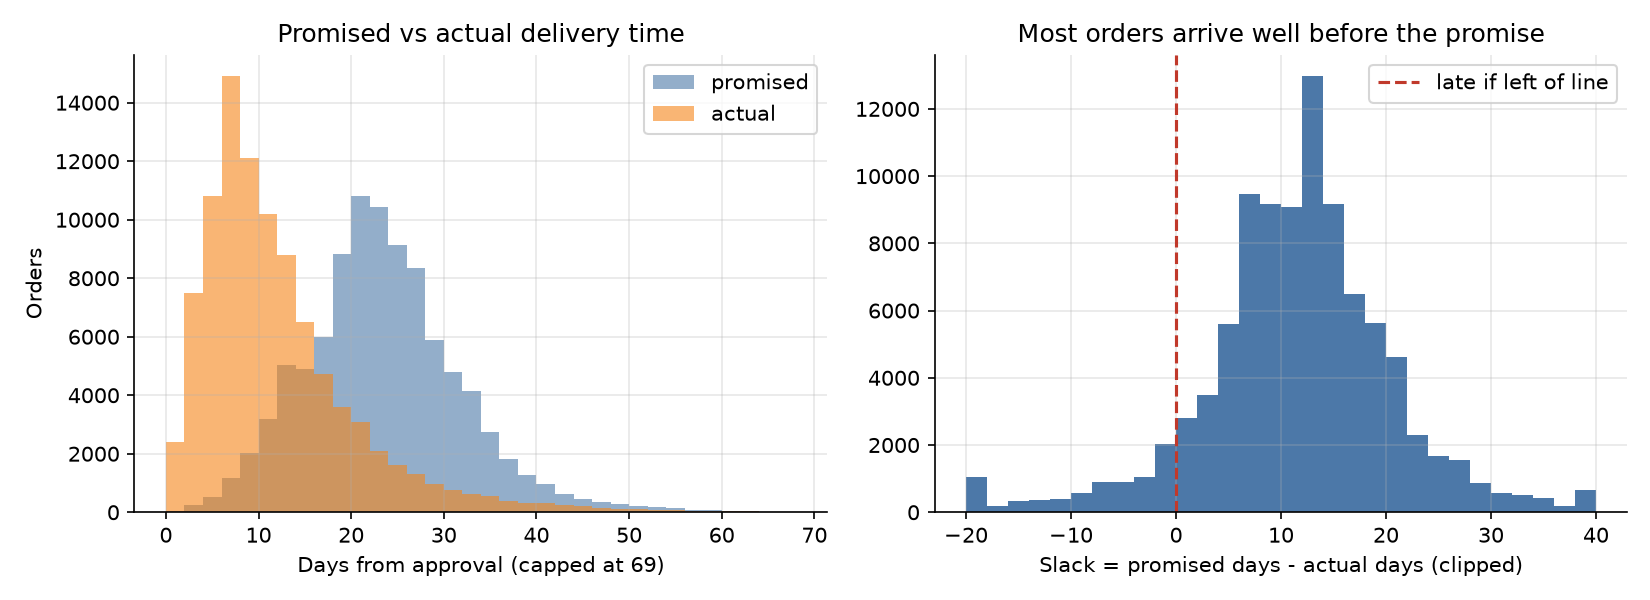

,count,mean,std,min,10%,50%,90%,max
promised_days,"94,937.000",23.500,8.700,0.300,12.900,22.900,33.900,153.600
delivery_days,"94,937.000",12.200,9.500,0.000,3.900,10.000,22.700,208.500
slack_days,"94,937.000",11.200,10.200,-189.000,1.200,12.000,21.300,146.000



**Inference.**
- The median promise is **23 days**, the median actual delivery is
  **10 days**. Olist's estimate is deliberately conservative.
- **74.4%** of orders arrive at least a week before the promised date, and only
  **8.1%** arrive after it (slack below zero; the date-level target differs slightly because
  it compares calendar dates).
- So lateness is the *tail* of a skewed process: a few orders blow through a big cushion.
  **Promised days itself should be a strong feature** (tight promise -> higher risk), and so
  should anything that predicts a long delivery (distance, handling time, seller track record).


In [5]:
summary = eda.plot_promise_vs_actual(df)
show("eda_promise_vs_actual.png")
display(summary.T)
early7 = (df["slack_days"] >= 7).mean()
neg = (df["slack_days"] < 0).mean()
Markdown(f"""
**Inference.**
- The median promise is **{df["promised_days"].median():.0f} days**, the median actual delivery is
  **{df["delivery_days"].median():.0f} days**. Olist's estimate is deliberately conservative.
- **{pct(early7)}** of orders arrive at least a week before the promised date, and only
  **{pct(neg)}** arrive after it (slack below zero; the date-level target differs slightly because
  it compares calendar dates).
- So lateness is the *tail* of a skewed process: a few orders blow through a big cushion.
  **Promised days itself should be a strong feature** (tight promise -> higher risk), and so
  should anything that predicts a long delivery (distance, handling time, seller track record).
""")

## 4. Where does lateness happen? Geography
**Why we ask:** Brazil is huge and its logistics are uneven. Distance and region should matter
a lot; we want to see *how much*, and whether the effect is about the **customer's** region, the
**seller's** region, or the **route** between them.

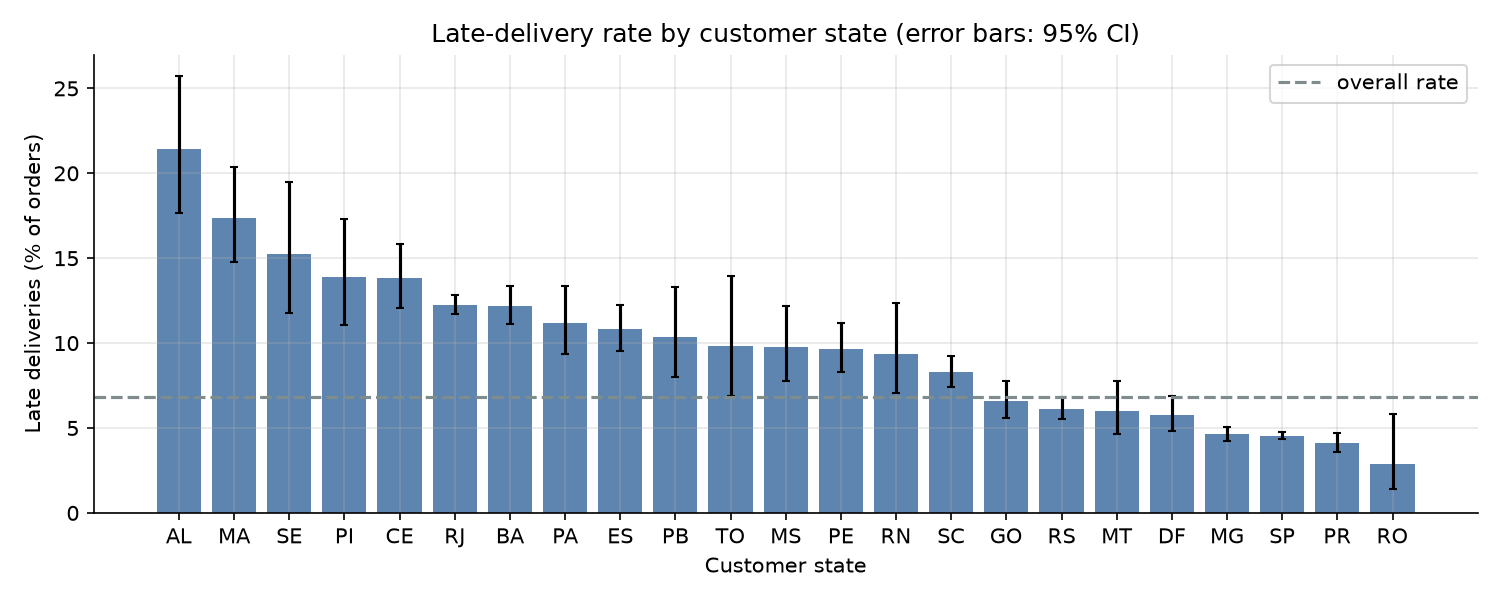

,customer_state,orders,late_rate,ci_low,ci_high
0,AL,397,0.214,0.177,0.257
6,MA,713,0.174,0.148,0.203
20,SE,335,0.152,0.118,0.195
13,PI,475,0.139,0.111,0.173
2,CE,1273,0.138,0.120,0.158


In [6]:
cust = eda.plot_state_rates(df, "customer_state", "eda_customer_state.png", "Customer")
show("eda_customer_state.png")
display(cust.head(5)[["customer_state", "orders", "late_rate", "ci_low", "ci_high"]])

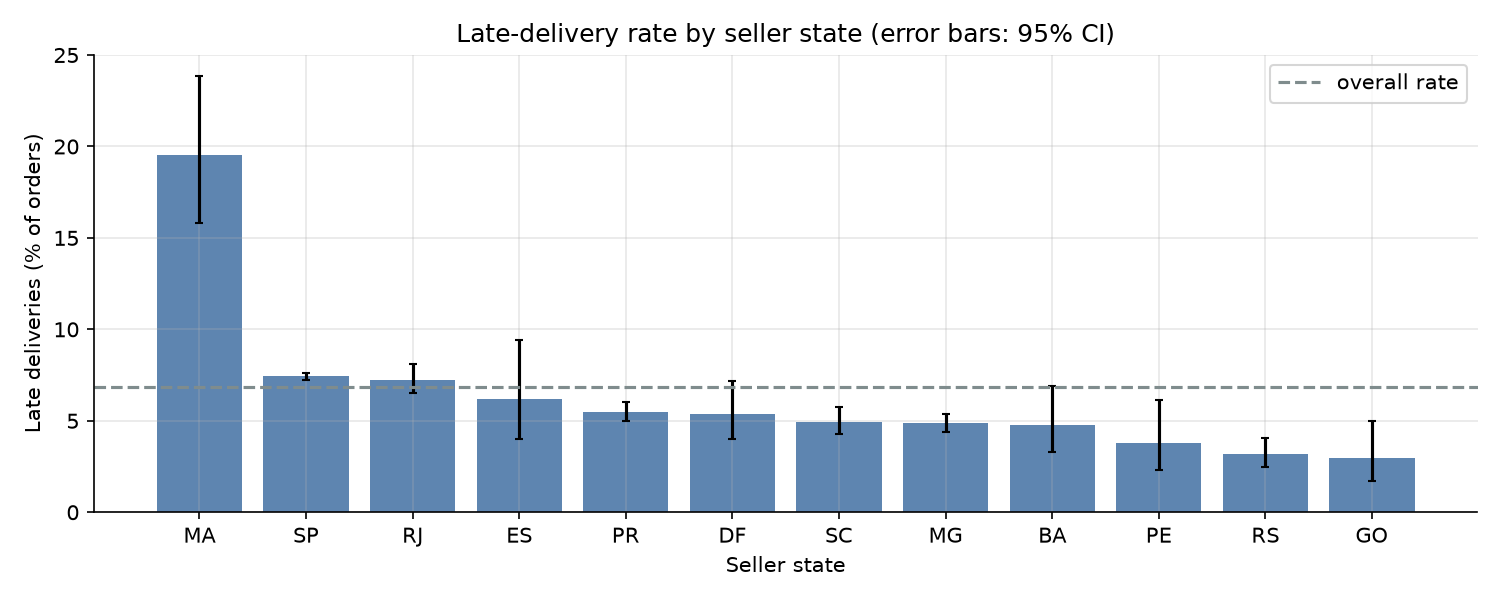


**Inference.**
- By **customer** state, the worst state is **AL** at 21.4%
  (397 orders), the best is **RO** at 2.9%.
- By **seller** state the range is 2.9% (GO) to
  19.5% (MA) among states with at least 200 orders.
- The spread across states is similar on the customer side
  (18.5 pp) and the seller side
  (16.6 pp): both *where the parcel starts*
  and *where it is going* matter, so we keep features for both ends.
- Error bars are 95% Wilson intervals. States with overlapping bars are not reliably different,
  which is why Phase 4 will use **shrinkage** for rate-based features instead of raw rates.


In [7]:
sell = eda.plot_state_rates(df, "seller_state", "eda_seller_state.png", "Seller")
show("eda_seller_state.png")
w_c, b_c = cust.iloc[0], cust.iloc[-1]
w_s, b_s = sell.iloc[0], sell.iloc[-1]
Markdown(f"""
**Inference.**
- By **customer** state, the worst state is **{w_c["customer_state"]}** at {pct(w_c["late_rate"])}
  ({int(w_c["orders"]):,} orders), the best is **{b_c["customer_state"]}** at {pct(b_c["late_rate"])}.
- By **seller** state the range is {pct(b_s["late_rate"])} ({b_s["seller_state"]}) to
  {pct(w_s["late_rate"])} ({w_s["seller_state"]}) among states with at least 200 orders.
- The spread across states is similar on the customer side
  ({(cust["late_rate"].max() - cust["late_rate"].min()) * 100:.1f} pp) and the seller side
  ({(sell["late_rate"].max() - sell["late_rate"].min()) * 100:.1f} pp): both *where the parcel starts*
  and *where it is going* matter, so we keep features for both ends.
- Error bars are 95% Wilson intervals. States with overlapping bars are not reliably different,
  which is why Phase 4 will use **shrinkage** for rate-based features instead of raw rates.
""")

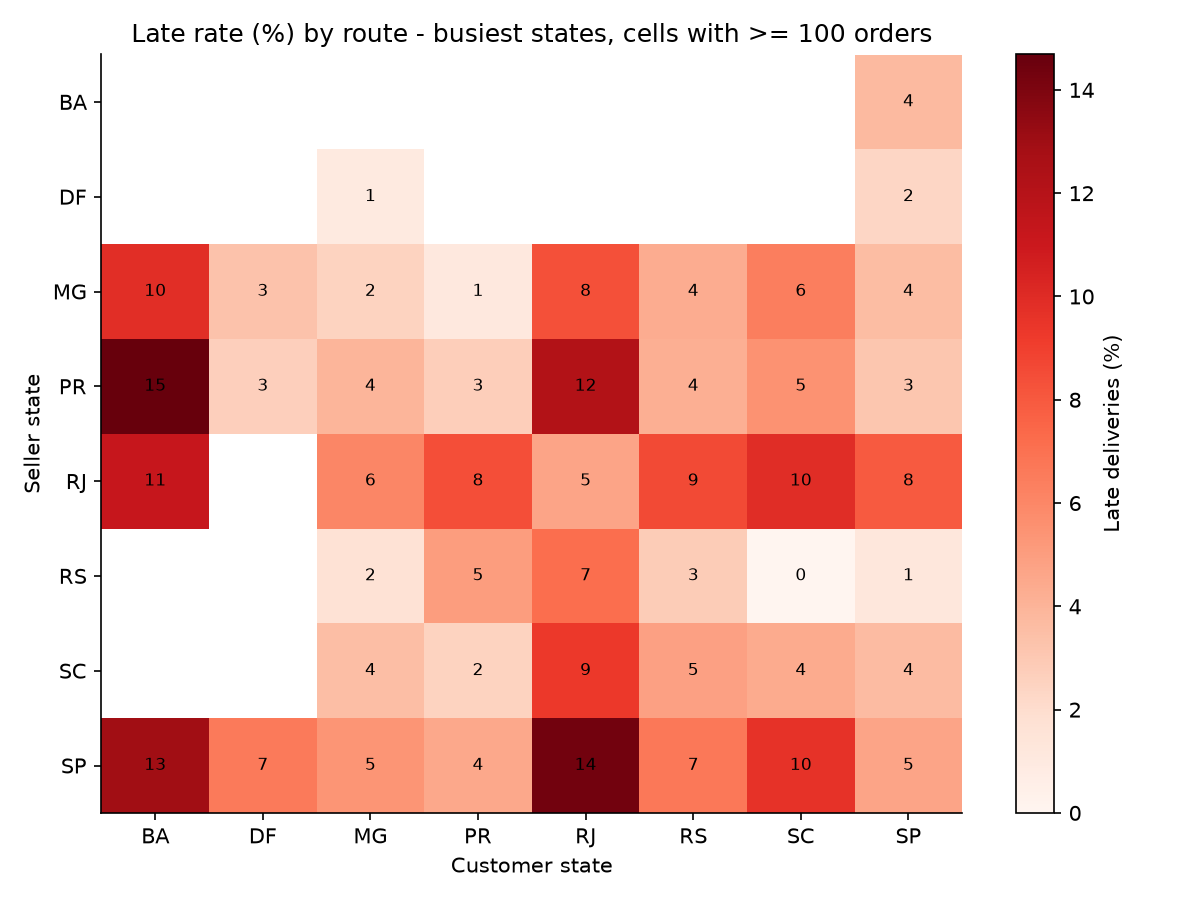

,orders,late_rate
same_state,,
different states,61133,0.081
same state,33804,0.045


In [8]:
route = eda.plot_route_heatmap(df)
show("eda_route_heatmap.png")
same = df.groupby("same_state")["is_late"].agg(["size", "mean"])
same.index = same.index.map({True: "same state", False: "different states"})
display(same.rename(columns={"size": "orders", "mean": "late_rate"}))

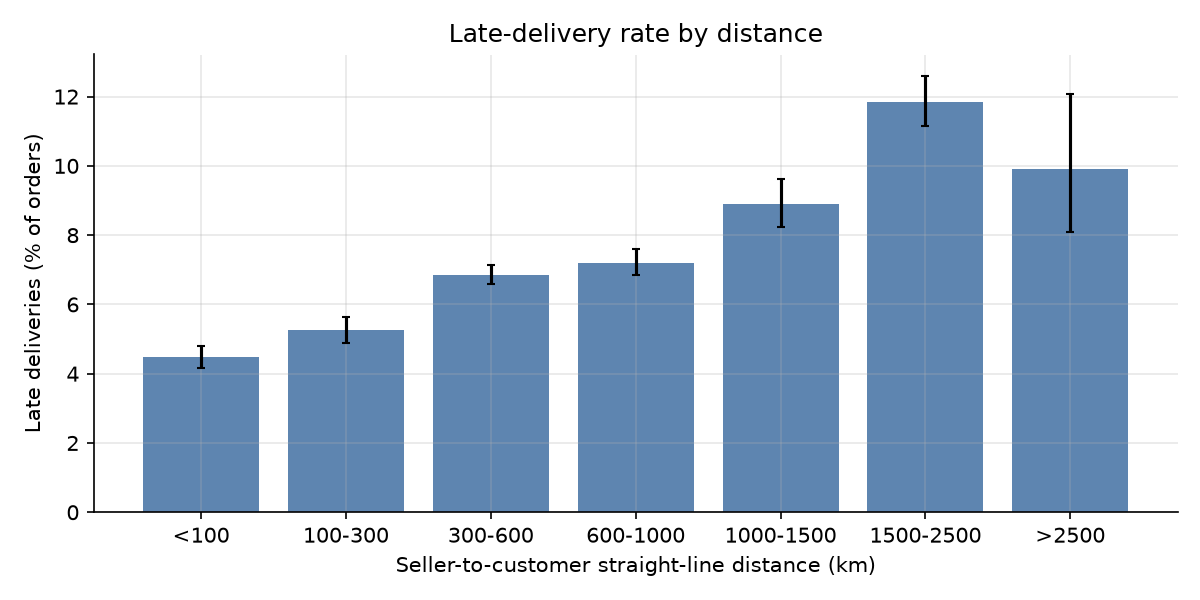

,distance_bucket,orders,late_rate,ci_low,ci_high
0,<100,17384,0.045,0.042,0.048
1,100-300,13139,0.053,0.049,0.056
2,300-600,31143,0.069,0.066,0.071
3,600-1000,17934,0.072,0.068,0.076
4,1000-1500,6564,0.089,0.082,0.096
5,1500-2500,7904,0.119,0.112,0.126
6,>2500,869,0.099,0.081,0.121



**Inference.**
- Late rate rises from **4.5%** for deliveries under 100 km to a peak of
  **11.9%** in the **1500-2500 km** band: distance is a first-order
  driver, as expected. The very longest band is not higher than the one before it, but it is also
  the smallest (869 orders) with a wide interval, so we do not read
  anything into that dip.
- The route heatmap shows late rates differ a lot between cells, i.e. *which* seller state ships
  to *which* customer state is informative (read along a row to see one seller state's
  destinations). Whether routes add information **beyond** distance is a question for the model
  explanations in Phase 8; for now it justifies **route-level history** and **region** features.
- Same-state deliveries are late 4.5% of the time vs
  8.1% across states.


In [9]:
dist = eda.plot_distance_rates(df)
show("eda_distance_rates.png")
display(dist[["distance_bucket", "orders", "late_rate", "ci_low", "ci_high"]])
near, far = dist.iloc[0], dist.loc[dist["late_rate"].idxmax()]
Markdown(f"""
**Inference.**
- Late rate rises from **{pct(near["late_rate"])}** for deliveries under 100 km to a peak of
  **{pct(far["late_rate"])}** in the **{far["distance_bucket"]} km** band: distance is a first-order
  driver, as expected. The very longest band is not higher than the one before it, but it is also
  the smallest ({int(dist.iloc[-1]["orders"]):,} orders) with a wide interval, so we do not read
  anything into that dip.
- The route heatmap shows late rates differ a lot between cells, i.e. *which* seller state ships
  to *which* customer state is informative (read along a row to see one seller state's
  destinations). Whether routes add information **beyond** distance is a question for the model
  explanations in Phase 8; for now it justifies **route-level history** and **region** features.
- Same-state deliveries are late {pct(same.loc["same state", "mean"])} of the time vs
  {pct(same.loc["different states", "mean"])} across states.
""")

## 5. Does the product category matter?
**Why we ask:** bulky or fragile categories travel differently; but categories also differ in
*who sells them* and *where they go*, so we treat this as a hint, not a proof.

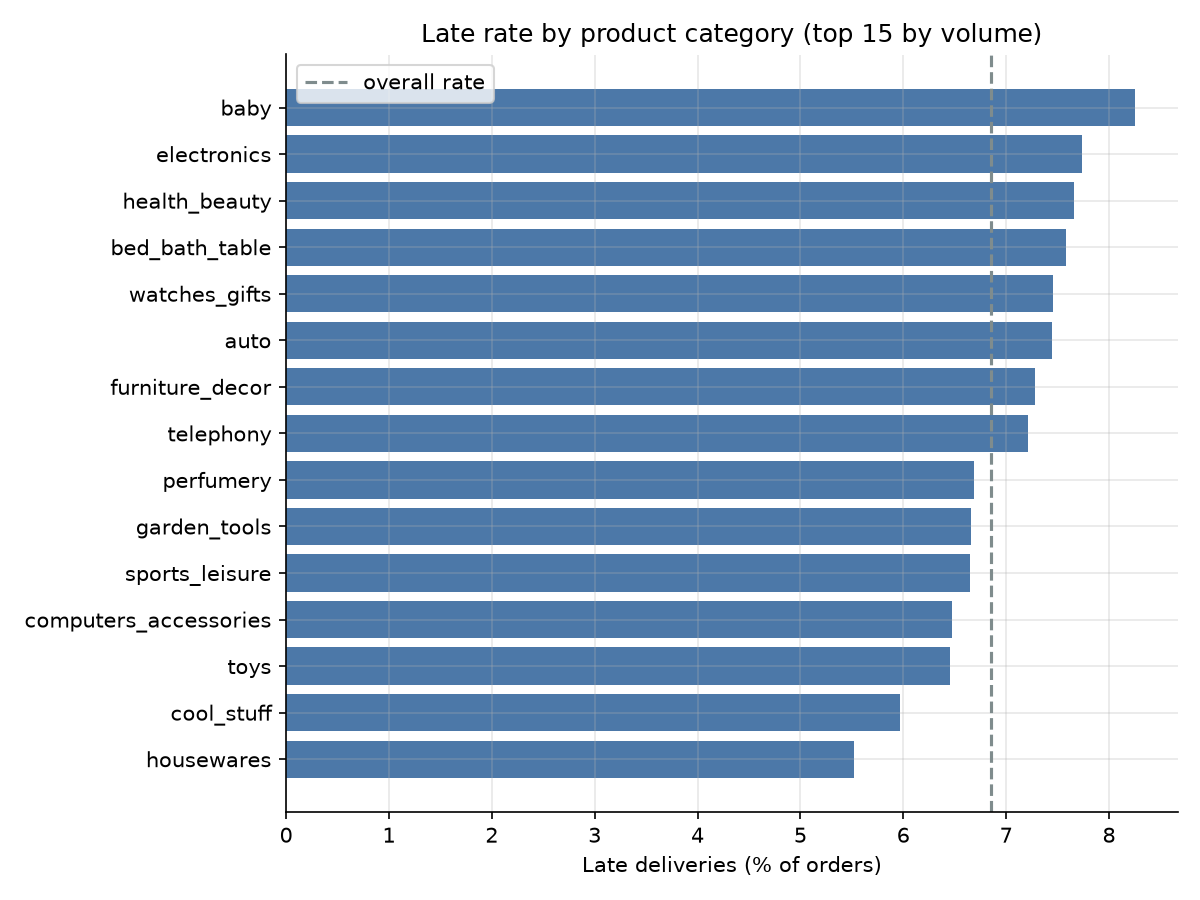


**Inference.** Among the 15 most common categories the late rate runs from
**5.5%** (`housewares`) to **8.3%** (`baby`).
Differences exist but are modest next to geography and time. We will collapse categories into
~10-15 groups (rare ones -> "other") so the model does not memorise tiny categories.


In [10]:
cat = eda.plot_category_rates(df)
show("eda_category_rates.png")
hi_c, lo_c = cat.iloc[-1], cat.iloc[0]
Markdown(f"""
**Inference.** Among the 15 most common categories the late rate runs from
**{pct(lo_c["late_rate"])}** (`{lo_c["category"]}`) to **{pct(hi_c["late_rate"])}** (`{hi_c["category"]}`).
Differences exist but are modest next to geography and time. We will collapse categories into
~10-15 groups (rare ones -> "other") so the model does not memorise tiny categories.
""")

## 6. Does *when* you order matter?
**Why we ask:** weekend orders may sit until Monday; late-night approvals miss carrier cut-offs.

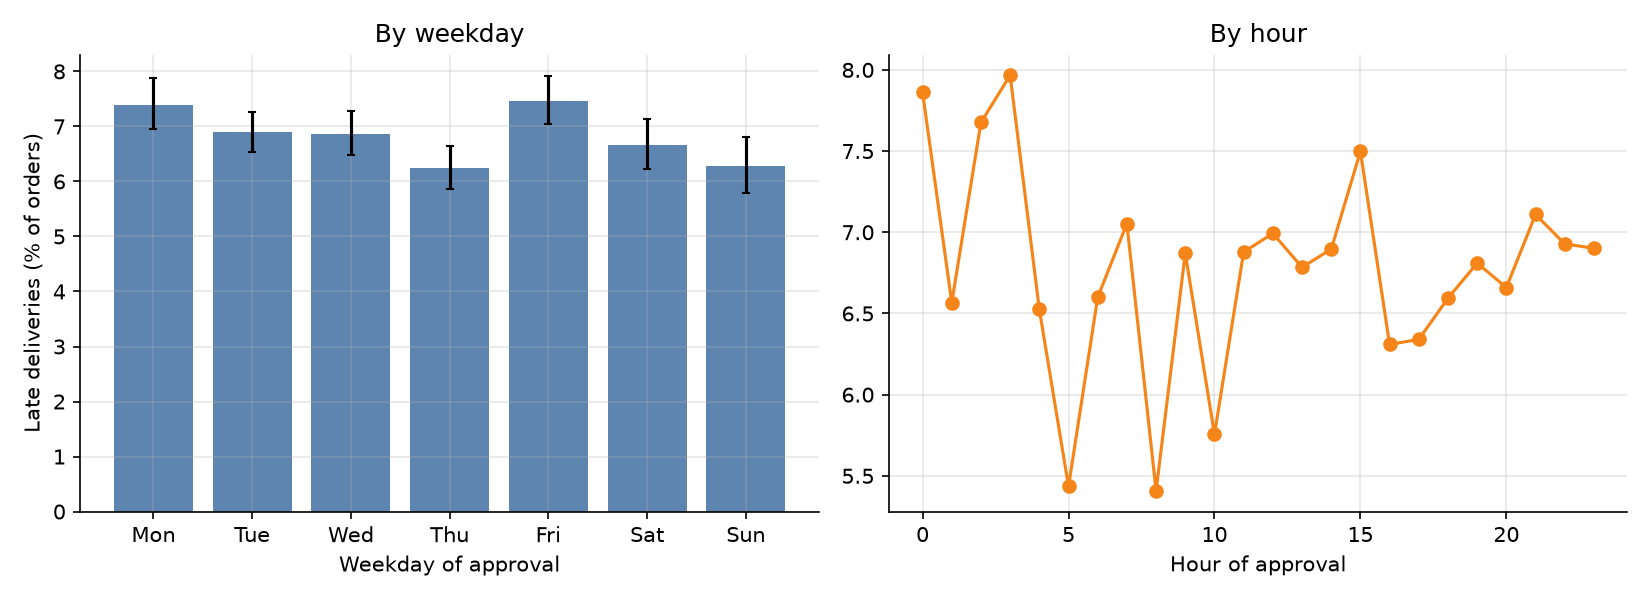

,approve_dow,orders,late_rate
0,Mon,12126,0.074
1,Tue,18282,0.069
2,Wed,15122,0.069
3,Thu,14880,0.062
4,Fri,14078,0.075
5,Sat,11751,0.067
6,Sun,8698,0.063



**Inference.** Across weekdays the late rate varies by only **1.2 percentage points**
(max minus min). Day-of-week and hour carry at most a weak signal compared with geography and
the promise window. We keep them as cheap calendar features (the model can ignore them), but we
do not expect them to be headline reasons.


In [11]:
dow, hour = eda.plot_time_of_week(df)
show("eda_time_of_week.png")
display(dow[["approve_dow", "orders", "late_rate"]])
spread = dow["late_rate"].max() - dow["late_rate"].min()
Markdown(f"""
**Inference.** Across weekdays the late rate varies by only **{spread * 100:.1f} percentage points**
(max minus min). Day-of-week and hour carry at most a weak signal compared with geography and
the promise window. We keep them as cheap calendar features (the model can ignore them), but we
do not expect them to be headline reasons.
""")

## 7. Black Friday: did the rush cause lateness?
**Why we ask:** the spike in November 2017 is the most famous episode in this dataset. We want
to know whether orders approved *around* Black Friday were particularly affected.

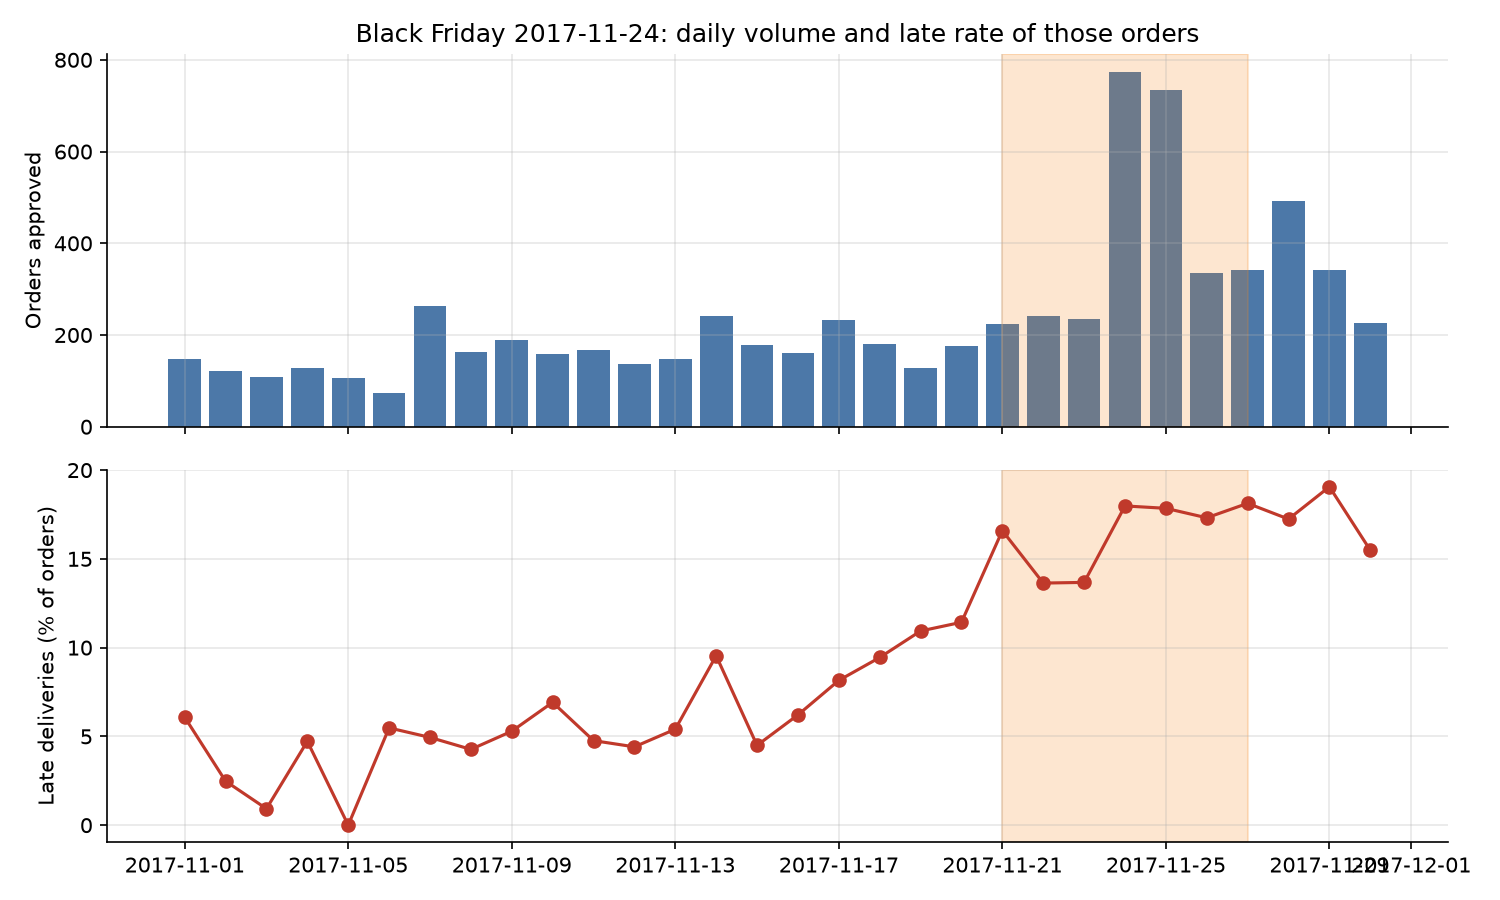


**Inference.** Orders approved within the configured window around Black Friday
(3 days either side, 2,883 orders) were
late **17.1%** of the time, versus **9.0%** for the rest
of that month. A holiday-rush flag is therefore a legitimate, leak-free feature (known at approval time).
*Hypothesis, not tested here:* the cause is carrier/seller capacity under peak load rather than
anything about the individual order; Phase 8 explanations will show how the model uses the flag.


In [12]:
bf = eda.plot_black_friday(df, "2017-11")
show("eda_black_friday.png")
w = bf.attrs
Markdown(f"""
**Inference.** Orders approved within the configured window around Black Friday
({CFG["features"]["black_friday_window_days"]} days either side, {w["window_orders"]:,} orders) were
late **{pct(w["window_rate"])}** of the time, versus **{pct(w["month_rate_outside"])}** for the rest
of that month. A holiday-rush flag is therefore a legitimate, leak-free feature (known at approval time).
*Hypothesis, not tested here:* the cause is carrier/seller capacity under peak load rather than
anything about the individual order; Phase 8 explanations will show how the model uses the flag.
""")

## 8. What do the splits look like?
**Why we ask:** before locking train/validation/test dates we check that every split has enough
orders *and enough late orders* to train on, tune on and evaluate on.

In [13]:
s = CFG["splits"]
a = df["order_approved_at"]
bounds = {
    "train": (a <= pd.Timestamp(s["train_end"]) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)),
    "validation": a.between(
        pd.Timestamp(s["val_start"]), pd.Timestamp(s["val_end"]) + pd.Timedelta(days=1)
    ),
    "test": a >= pd.Timestamp(s["test_start"]),
}
rows = []
for name, m in bounds.items():
    x = df[m]
    rows.append(
        {
            "split": name,
            "from": x["order_approved_at"].min().date(),
            "to": x["order_approved_at"].max().date(),
            "orders": len(x),
            "late_orders": int(x["is_late"].sum()),
            "late_rate": x["is_late"].mean(),
        }
    )
split_tbl = pd.DataFrame(rows).set_index("split")
display(split_tbl)
v, te, tr = split_tbl.loc["validation"], split_tbl.loc["test"], split_tbl.loc["train"]
Markdown(f"""
**Inference.**
- Every split holds well over a thousand late orders, so metrics and bootstrap intervals are
  usable: train **{int(tr["late_orders"]):,}**, validation **{int(v["late_orders"]):,}**,
  test **{int(te["late_orders"]):,}**.
- **Honest caveat - distribution shift:** the late rate is **{pct(tr["late_rate"])}** in train,
  **{pct(v["late_rate"])}** in validation (it contains the early-2018 surge) and
  **{pct(te["late_rate"])}** in test. A model calibrated on validation will tend to
  *over-predict* risk on test. We will measure and report this instead of hiding it; it is a
  realistic version of what happens in production.
- Alternatives I considered (moving the boundaries by a month) shrank the test set's late orders
  substantially, so the proposed dates in `configs/config.yaml` are kept.
""")

,from,to,orders,late_orders,late_rate
split,,,,,
train,2016-09-15,2018-01-31,50603,2852,0.056
validation,2018-02-01,2018-04-30,20241,2556,0.126
test,2018-05-01,2018-08-18,24093,1096,0.045



**Inference.**
- Every split holds well over a thousand late orders, so metrics and bootstrap intervals are
  usable: train **2,852**, validation **2,556**,
  test **1,096**.
- **Honest caveat - distribution shift:** the late rate is **5.6%** in train,
  **12.6%** in validation (it contains the early-2018 surge) and
  **4.5%** in test. A model calibrated on validation will tend to
  *over-predict* risk on test. We will measure and report this instead of hiding it; it is a
  realistic version of what happens in production.
- Alternatives I considered (moving the boundaries by a month) shrank the test set's late orders
  substantially, so the proposed dates in `configs/config.yaml` are kept.


## 9. Take-aways and what they mean for the next phases

In [14]:
Markdown(f"""
| # | Finding | Consequence |
|---|---|---|
| 1 | Only {pct(base_rate)} of orders are late | Use PR-AUC, precision@k, lift; never accuracy |
| 2 | Late rate swings strongly by month | Time-based splits; month-by-month test reporting; recent-network-delay feature |
| 3 | Estimates are generous - most orders arrive early | Promised days and slack-related features are central |
| 4 | State and distance show the largest spreads; routes look informative | Distance, region, route-history features with shrinkage |
| 5 | Category effects are modest | Grouped categories, no memorisation |
| 6 | Weekday/hour effects are weak | Keep as cheap calendar features |
| 7 | Black Friday window is worse than its month | Holiday-rush feature (config-driven) |
| 8 | Test period is easier than validation | Expect calibration drift; report honestly |
""")


| # | Finding | Consequence |
|---|---|---|
| 1 | Only 6.9% of orders are late | Use PR-AUC, precision@k, lift; never accuracy |
| 2 | Late rate swings strongly by month | Time-based splits; month-by-month test reporting; recent-network-delay feature |
| 3 | Estimates are generous - most orders arrive early | Promised days and slack-related features are central |
| 4 | State and distance show the largest spreads; routes look informative | Distance, region, route-history features with shrinkage |
| 5 | Category effects are modest | Grouped categories, no memorisation |
| 6 | Weekday/hour effects are weak | Keep as cheap calendar features |
| 7 | Black Friday window is worse than its month | Holiday-rush feature (config-driven) |
| 8 | Test period is easier than validation | Expect calibration drift; report honestly |
